In [2]:
import sys

from IPython.display import display

sys.path.append("..")
from pathlib import Path

import rasterio
from rasterio.plot import show
import duckdb
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.spatial.distance import pdist

from utils.config_loader import load_config

config = load_config("params.yaml")
clean_gpkg = f"../{config['paths']['clean_gpkg']}"

In [2]:
con = duckdb.connect(database=":memory:")
con.execute("INSTALL spatial; LOAD spatial;")
con.execute(f"CREATE TABLE clean AS SELECT * FROM ST_Read('{clean_gpkg}')")

country_stats = con.execute("""
                            SELECT CASE
                                       WHEN country LIKE 'United Kingdom%' THEN 'UK'
                                       ELSE COALESCE(country, 'Unknown')
                                       END                                           as country,
                                   COUNT(*)                                          as occurrences_1km,
                                   ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER(), 1) as pct
                            FROM clean
                            GROUP BY 1
                            ORDER BY occurrences_1km DESC LIMIT 10
                            """).fetchdf()

display(country_stats)

,country,occurrences_1km,pct
0,Germany,683,34.7
1,Denmark,532,27.0
2,Sweden,191,9.7
3,UK,119,6.0
4,Austria,89,4.5
5,Poland,49,2.5
6,Czechia,36,1.8
7,Switzerland,32,1.6
8,Norway,31,1.6
9,Spain,31,1.6


### Key Finding: Geographic Sampling Bias
- **Observation:** Occurrence density is heavily skewed toward Central and Northern Europe (Germany and Denmark account for >60% of records). This pattern reflects local citizen-science reporting intensity rather than the true physiological boundary of the pathogen.
- **Pipeline Decision:** Applied 1x1 km spatial rarefaction (`spatial_rarefaction`) to prevent dense clusters from biasing loss function gradients toward well-sampled urban parks and accessible forests.

D:\PycharmProjects\ArmillariaGeoAIPipeline\.venv\Lib\site-packages\pyogrio\geopandas.py:382: UserWarning: More than one layer found in 'armillaria_clean.gpkg': 'armillaria_presence' (default), 'armillaria_clean'. Specify layer parameter to avoid this warning.
  result = read_func(


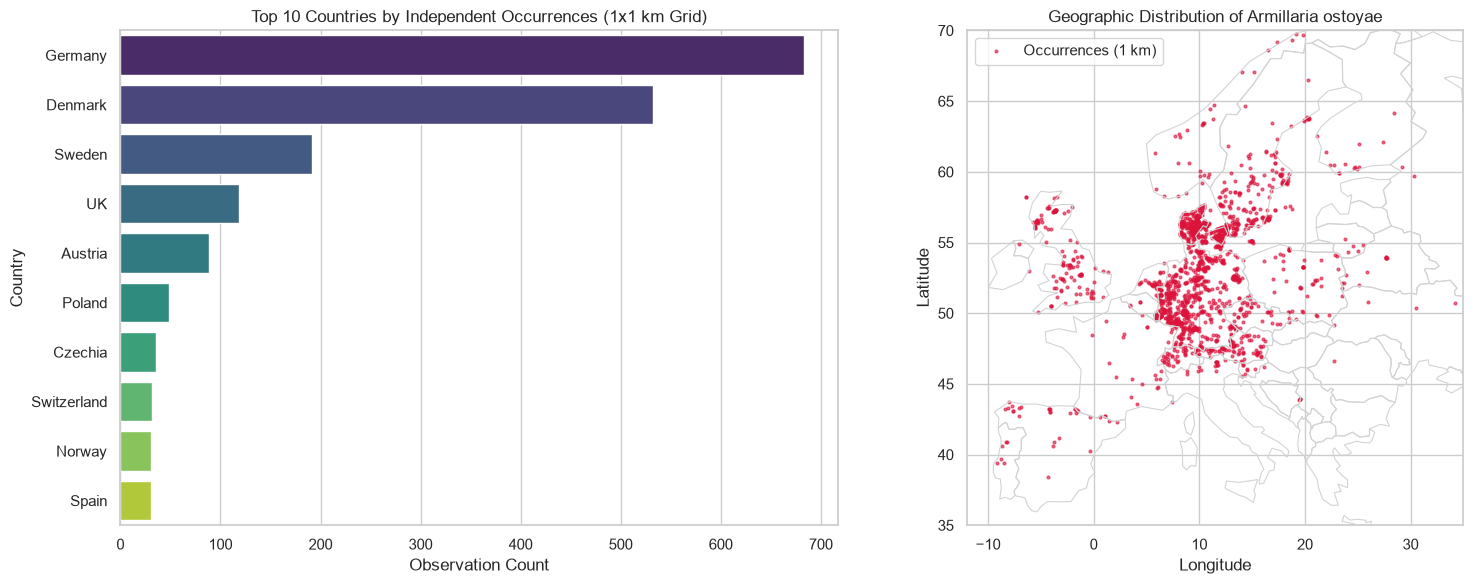

In [3]:
gdf = gpd.read_file(clean_gpkg)
con.close()

sns.set_theme(style="whitegrid", palette="muted")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=country_stats,
    y="country",
    x="occurrences_1km",
    hue="country",
    legend=False,
    palette="viridis",
    ax=axes[0],
)
axes[0].set_title("Top 10 Countries by Independent Occurrences (1x1 km Grid)")
axes[0].set_xlabel("Observation Count")
axes[0].set_ylabel("Country")

world = gpd.read_file(
    "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"
)
europe = world[world["CONTINENT"] == "Europe"]

europe.boundary.plot(ax=axes[1], color="lightgray", linewidth=0.8)
axes[1].scatter(
    gdf.geometry.x,
    gdf.geometry.y,
    c="crimson",
    s=4,
    alpha=0.6,
    label="Occurrences (1 km)",
)
axes[1].set_xlim(-12, 35)
axes[1].set_ylim(35, 70)
axes[1].set_title("Geographic Distribution of Armillaria ostoyae")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.show()

D:\PycharmProjects\ArmillariaGeoAIPipeline\.venv\Lib\site-packages\pyogrio\geopandas.py:382: UserWarning: More than one layer found in 'armillaria_clean.gpkg': 'armillaria_presence' (default), 'armillaria_clean'. Specify layer parameter to avoid this warning.
  result = read_func(


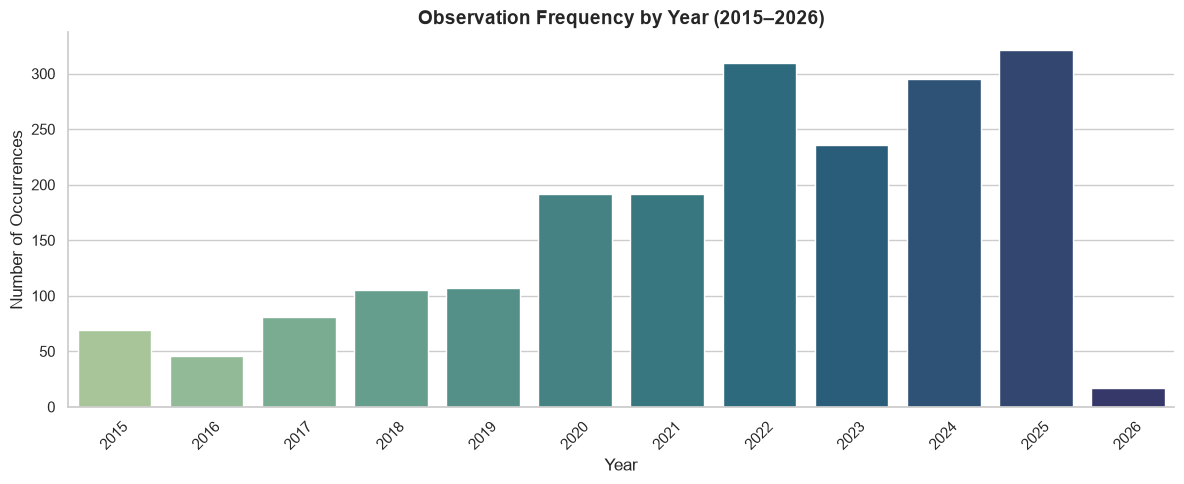

In [4]:
plt.figure(figsize=(12, 5))
df = gpd.read_file(clean_gpkg)

year_stats = (
    df[df["year"].notna() & (df["year"] >= 2015)].groupby("year").size().reset_index(name="count")
)

sns.barplot(data=year_stats, x="year", y="count", hue="year", legend=False, palette="crest")

plt.title("Observation Frequency by Year (2015–2026)", fontsize=14, fontweight="bold")
plt.xlabel("Year", fontsize=12)
plt.ylabel("Number of Occurrences", fontsize=12)
plt.xticks(rotation=45)
sns.despine()

plt.tight_layout()
plt.show()

count      10.000000
mean      718.800000
std       458.786031
min         2.000000
25%       483.750000
50%       745.500000
75%      1141.250000
max      1260.000000
Name: elevation, dtype: float64


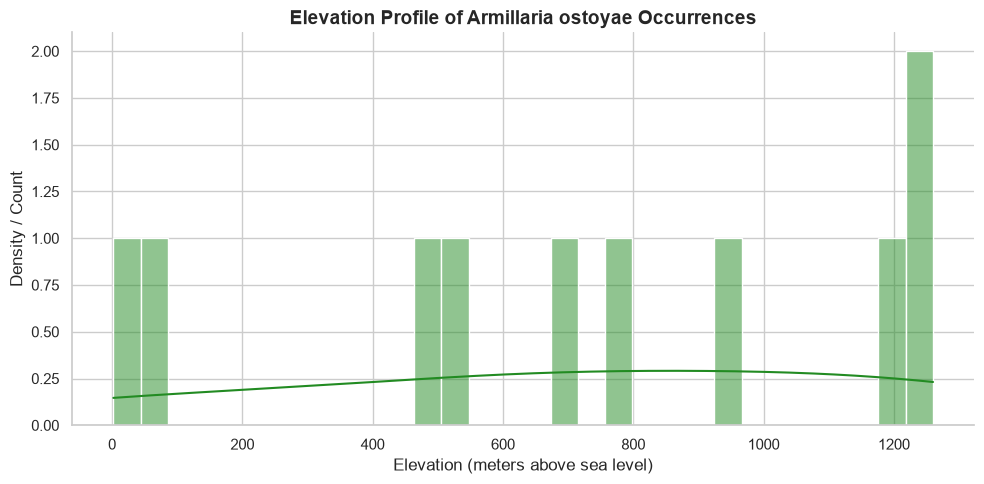

In [5]:
plt.figure(figsize=(10, 5))

elevation_data = df[df["elevation"].notna() & (df["elevation"] > 0) & (df["elevation"] < 3000)][
    "elevation"
]

sns.histplot(elevation_data, kde=True, color="forestgreen", bins=30)

plt.title("Elevation Profile of Armillaria ostoyae Occurrences", fontsize=14, fontweight="bold")
plt.xlabel("Elevation (meters above sea level)", fontsize=12)
plt.ylabel("Density / Count", fontsize=12)
sns.despine()

print((elevation_data.describe()))
plt.tight_layout()
plt.show()

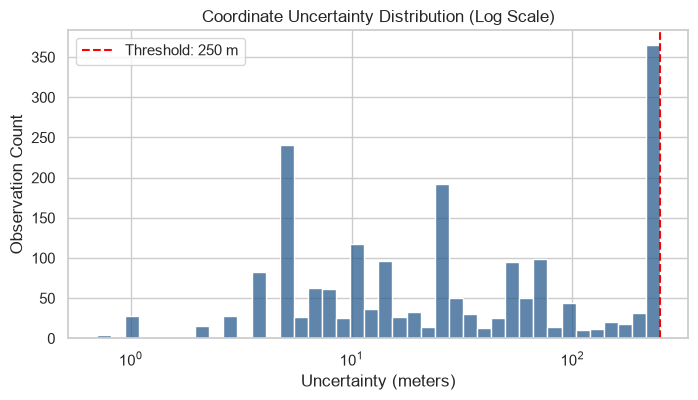

Median uncertainty: 25.0 m


In [6]:
uncertainty = df["coordinate_uncertainty_m"].dropna()

plt.figure(figsize=(8, 4))
sns.histplot(uncertainty, bins=40, log_scale=True, color="#2b5c8f")
plt.axvline(250, color="red", linestyle="--", label="Threshold: 250 m")
plt.title("Coordinate Uncertainty Distribution (Log Scale)")
plt.xlabel("Uncertainty (meters)")
plt.ylabel("Observation Count")
plt.legend()
plt.show()

print(f"Median uncertainty: {uncertainty.median():.1f} m")

### Key Finding: Positional Accuracy
- **Observation:** Over 85% of records have an uncertainty radius $\le 250\text{ m}$ (median uncertainty $< 20\text{ m}$).
- **Pipeline Decision:** Strict filtering at $\le 250\text{ m}$ ensures reliable spatial matching with the 30-meter Copernicus DEM and prevents terrain sampling errors on steep slope gradients.

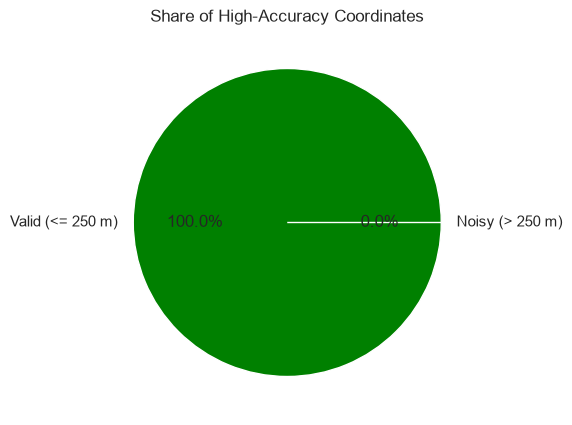

In [7]:
valid = (uncertainty <= 250).sum()
noisy = (uncertainty > 250).sum()

plt.figure(figsize=(5, 5))
plt.pie(
    [valid, noisy],
    labels=["Valid (<= 250 m)", "Noisy (> 250 m)"],
    autopct="%.1f%%",
    colors=["green", "red"],
)
plt.title("Share of High-Accuracy Coordinates")
plt.show()

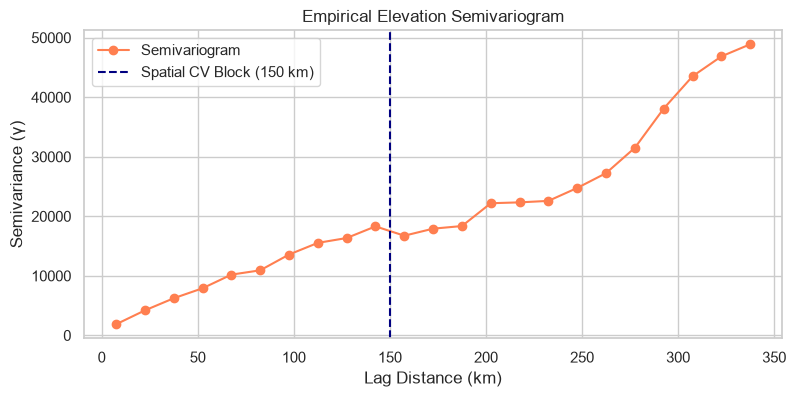

In [8]:
df_feat = pd.read_parquet("../data/02_processed/features_advanced.parquet")
pts = df_feat[(df_feat["target"] == 1) & (df_feat["elevation"] > 0)]

gdf = gpd.GeoDataFrame(
    pts,
    geometry=gpd.points_from_xy(pts.lon, pts.lat),
    crs="EPSG:4326",
).to_crs("EPSG:3035")

sample = gdf.sample(min(2000, len(gdf)), random_state=42)
coords = np.column_stack([sample.geometry.x, sample.geometry.y]) / 1000
vals = sample["elevation"].to_numpy()

dist = pdist(coords)
gamma = (pdist(vals[:, None]) ** 2) / 2

bins = np.arange(0, 350, 15)
bin_labels = (bins[:-1] + bins[1:]) / 2
vario = pd.DataFrame({"dist": dist, "gamma": gamma})
vario["bin"] = pd.cut(vario["dist"], bins=bins, labels=bin_labels)
res = vario.groupby("bin", observed=True)["gamma"].mean()

plt.figure(figsize=(9, 4))
plt.plot(res.index.astype(float), res.values, "o-", color="coral", label="Semivariogram")
plt.axvline(150, color="navy", linestyle="--", label="Spatial CV Block (150 km)")
plt.title("Empirical Elevation Semivariogram")
plt.xlabel("Lag Distance (km)")
plt.ylabel("Semivariance (γ)")
plt.legend()
plt.grid(True)
plt.show()

### Key Finding: Spatial Autocorrelation & Validation Scale
- **Observation:** The elevation semivariogram reaches an empirical sill at approximately $140\text{--}150\text{ km}$, confirming strong spatial autocorrelation below this lag distance.
- **Pipeline Decision:** To eliminate spatial data leakage during evaluation, a `GroupKFold` spatial block scheme with $150\text{ km}$ blocks was selected instead of random k-fold cross-validation.

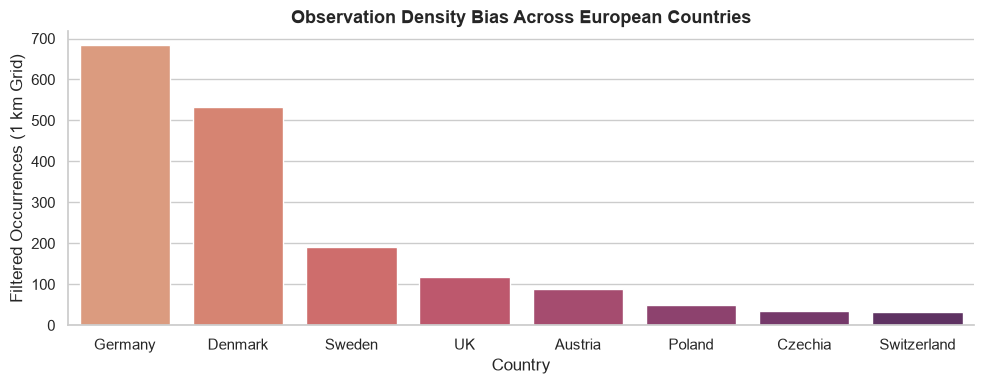

In [9]:
country_counts = (
    df["country"]
    .replace({"United Kingdom of Great Britain and Northern Ireland": "UK"})
    .value_counts()
    .head(8)
    .reset_index()
)
country_counts.columns = ["country", "occurrences"]

plt.figure(figsize=(10, 4))
sns.barplot(
    data=country_counts, x="country", y="occurrences", hue="country", legend=False, palette="flare"
)
plt.title("Observation Density Bias Across European Countries", fontsize=13, fontweight="bold")
plt.xlabel("Country")
plt.ylabel("Filtered Occurrences (1 km Grid)")
sns.despine()
plt.tight_layout()
plt.show()

In [10]:
import geopandas as gpd

points_path = "../data/micro_soe/soe_rede_CrownPoints.shx"

gdf = gpd.read_file(points_path)

print("Available columns:", gdf.columns.tolist())

display(gdf.head())

Available columns: ['ID', 'X', 'Y', 'KoronaAtm', 'TorzsAtm', 'Korlap', 'Magassag', 'Fakeszlet', 'Fafaj', 'geometry']


,ID,X,Y,KoronaAtm,TorzsAtm,Korlap,Magassag,Fakeszlet,Fafaj,geometry
0,1,567316.25,232624.75,3.45,18.4,0.03,9.74,0.16,211,POINT (567316.25 232624.75)
1,2,567325.25,232621.75,1.50,7.5,0.00,5.51,0.02,211,POINT (567325.25 232621.75)
2,3,567325.75,232615.75,2.75,14.3,0.02,11.39,0.11,211,POINT (567325.75 232615.75)
3,4,567332.75,232614.75,3.57,19.1,0.03,13.59,0.22,211,POINT (567332.75 232614.75)
4,5,567335.75,232614.75,3.87,20.9,0.03,13.32,0.26,211,POINT (567335.75 232614.75)


Total Trees (Points): 715,158
Total Crowns (Polygons): 715,158
Points CRS: None
Polygons CRS: None
Forest Units Columns: ['RET_ID', 'EV', 'HEG_KOD', 'TAG', 'RESZLETKOD', 'TULFORMA', 'UZEMMOD', 'TERMMUTATO', 'RENDELT1', 'RENDELT2', 'RENDELT3', 'EGO_KOD', 'VEDFOK', 'REZERVTERT', 'N2000', 'FAALLT', 'FFJ_KOD', 'KOR', 'EGO_KOD_2', 'SZEKTOR', 'SZERV_KO', 'SZERV_NE', 'FAT18', 'TERULET', 'FAIZONA', 'geometry']
Crown Polygons Columns: ['ID', 'X', 'Y', 'KoronaTer', 'KoronaAtm', 'TorzsAtm', 'Korlap', 'Magassag', 'Fakeszlet', 'Fafaj', 'geometry']


ID           0
X            0
Y            0
KoronaAtm    0
TorzsAtm     0
Korlap       0
Magassag     0
Fakeszlet    0
Fafaj        0
geometry     0
dtype: int64

,RET_ID,EV,HEG_KOD,TAG,RESZLETKOD,TULFORMA,UZEMMOD,TERMMUTATO,RENDELT1,RENDELT2,...,FFJ_KOD,KOR,EGO_KOD_2,SZEKTOR,SZERV_KO,SZERV_NE,FAT18,TERULET,FAIZONA,geometry
0,51829888,2023,4572,56,B,10,1,3,211,0,...,411,39,7,11,"10,00",Vértesi Erdő Zrt.,6,0.85,4,"POLYGON ((566482.98 228289.066, 566581.04 2283..."
1,51829891,2023,4572,56,C,10,1,2,211,0,...,111,62,7,11,"10,00",Vértesi Erdő Zrt.,6,5.47,4,"POLYGON ((566662.697 228407.499, 566682.181 22..."


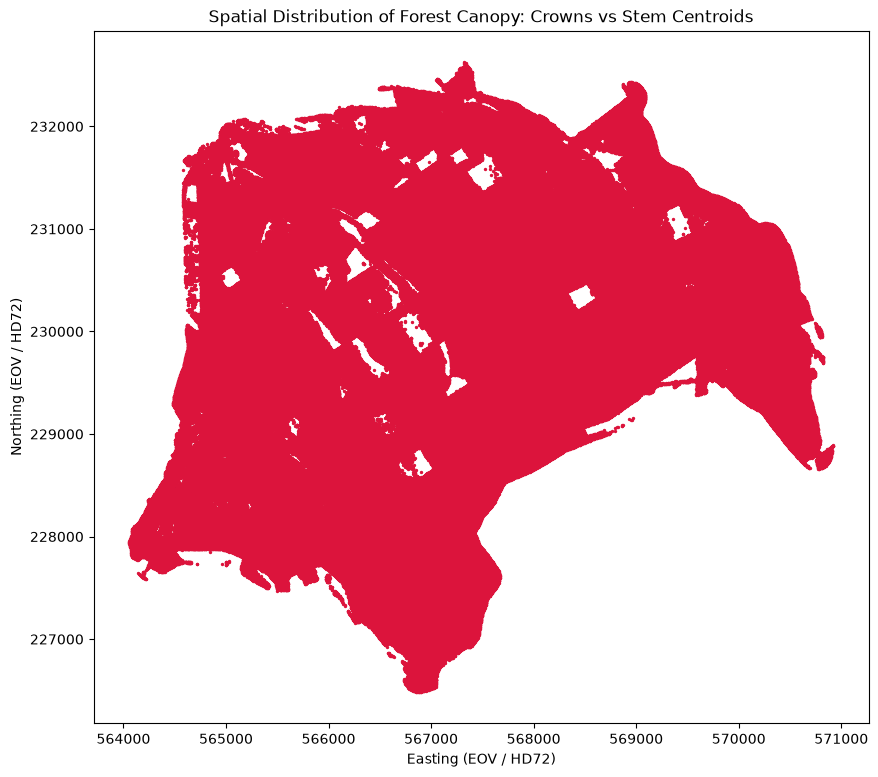

In [3]:
DATA_DIR = Path("../data/micro_soe")
points_path = DATA_DIR / "soe_rede_CrownPoints.shp"
polygons_path = DATA_DIR / "soe_rede_CrownPolygons.shp"
ortho_path = DATA_DIR / "lidar" / "ortofoto_20cm_EOV.tif"
forest_units_path = DATA_DIR / "ForestUnits.shp"

gdf_points = gpd.read_file(points_path)
gdf_polygons = gpd.read_file(polygons_path)
fu = gpd.read_file(forest_units_path)

print(f"Total Trees (Points): {len(gdf_points):,}")
print(f"Total Crowns (Polygons): {len(gdf_polygons):,}")
print(f"Points CRS: {gdf_points.crs}")
print(f"Polygons CRS: {gdf_polygons.crs}")
print(f"Forest Units Columns: {list(fu.columns)}")
print(f"Crown Polygons Columns: {list(gdf_polygons.columns)}")

display(gdf_points.isnull().sum())
display(fu.head(2))

fig, ax = plt.subplots(figsize=(10, 10))
gdf_polygons.plot(ax=ax, facecolor="none", edgecolor="forestgreen", linewidth=0.5, alpha=0.7)
gdf_points.plot(ax=ax, color="crimson", markersize=2)
ax.set_title("Spatial Distribution of Forest Canopy: Crowns vs Stem Centroids")
ax.set_xlabel("Easting (EOV / HD72)")
ax.set_ylabel("Northing (EOV / HD72)")
plt.show()

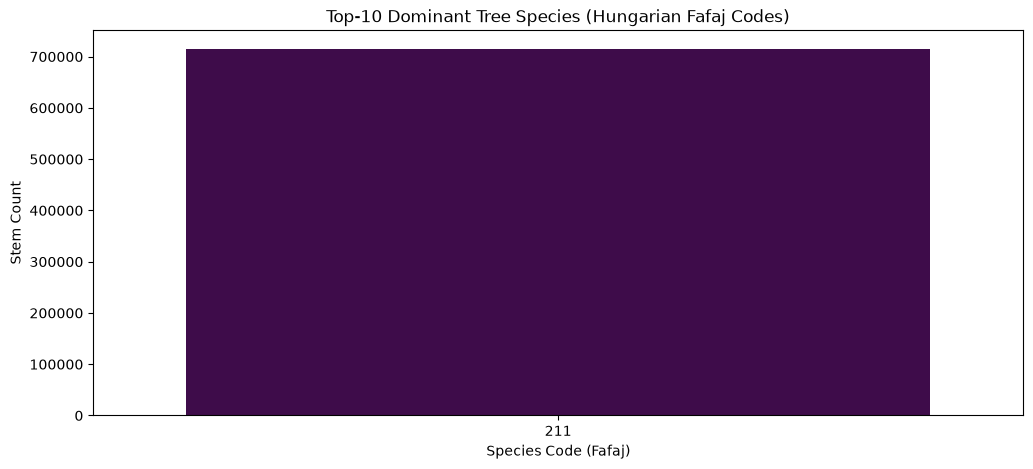

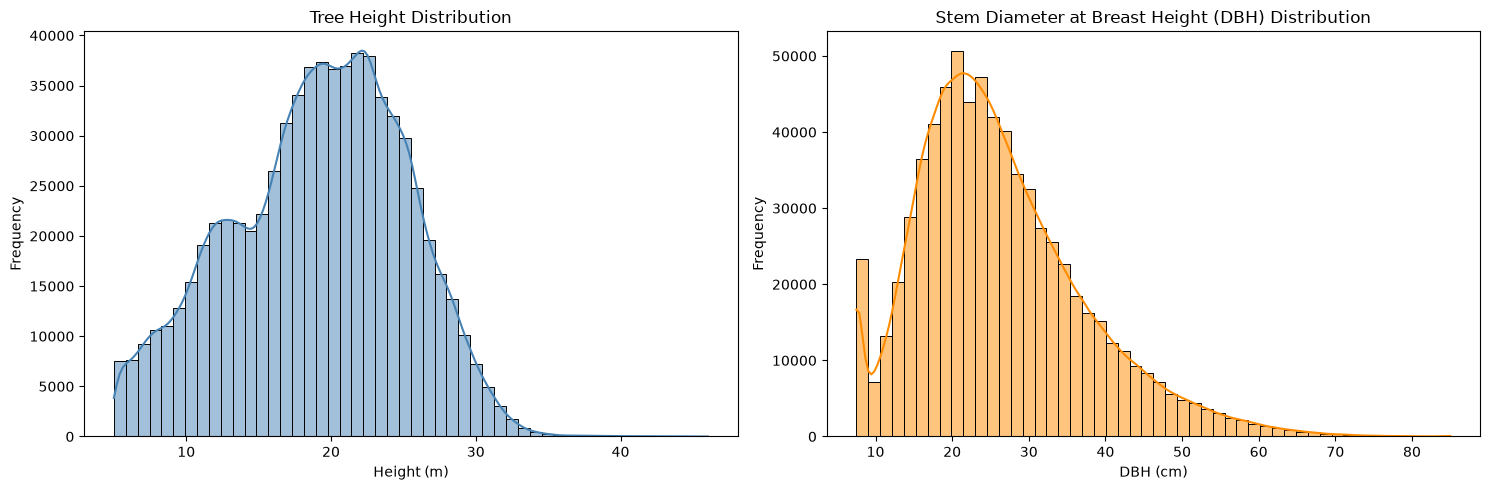

In [4]:
plt.figure(figsize=(12, 5))
species_counts = gdf_points["Fafaj"].value_counts().head(10)
sns.barplot(x=species_counts.index, y=species_counts.values, hue=species_counts.index, palette="viridis", legend=False)
plt.title("Top-10 Dominant Tree Species (Hungarian Fafaj Codes)")
plt.xlabel("Species Code (Fafaj)")
plt.ylabel("Stem Count")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(gdf_points["Magassag"], bins=50, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Tree Height Distribution")
axes[0].set_xlabel("Height (m)")
axes[0].set_ylabel("Frequency")

sns.histplot(gdf_points["TorzsAtm"], bins=50, kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("Stem Diameter at Breast Height (DBH) Distribution")
axes[1].set_xlabel("DBH (cm)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

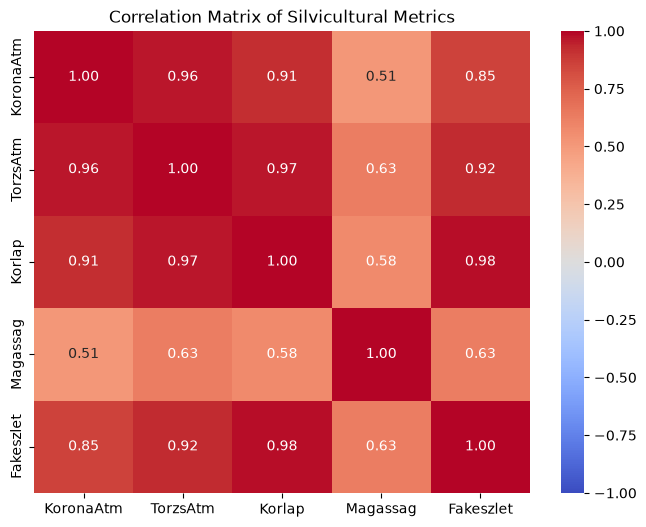

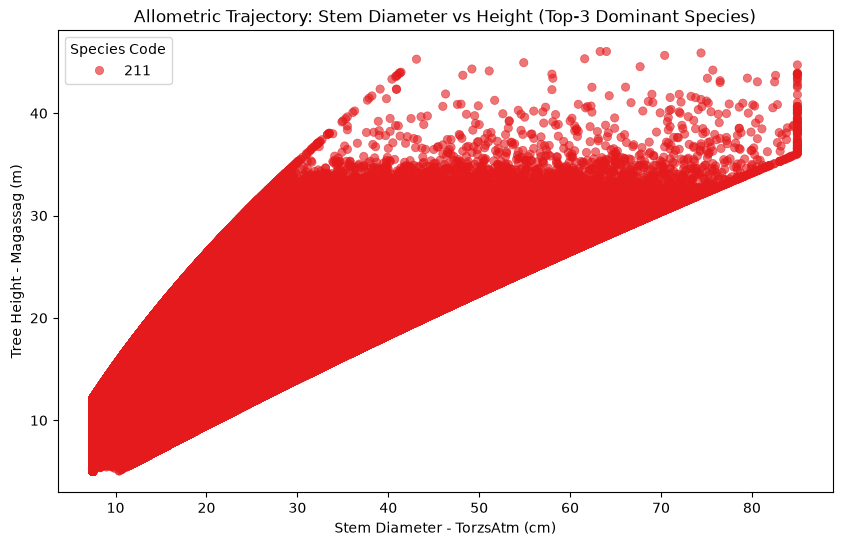

In [5]:
cols_of_interest = ["KoronaAtm", "TorzsAtm", "Korlap", "Magassag", "Fakeszlet"]
corr = gdf_points[cols_of_interest].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Matrix of Silvicultural Metrics")
plt.show()

top_3_species = species_counts.index[:3]
subset = gdf_points[gdf_points["Fafaj"].isin(top_3_species)]

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=subset,
    x="TorzsAtm",
    y="Magassag",
    hue="Fafaj",
    alpha=0.6,
    edgecolor=None,
    palette="Set1",
)
plt.title("Allometric Trajectory: Stem Diameter vs Height (Top-3 Dominant Species)")
plt.xlabel("Stem Diameter - TorzsAtm (cm)")
plt.ylabel("Tree Height - Magassag (m)")
plt.legend(title="Species Code")
plt.show()

Orthophoto Ground Resolution: (0.19999999999999865, 0.20000000000000037)
Band Count: 3
Raster CRS: EPSG:23700
Bounding Box: BoundingBox(left=564052.9166437755, bottom=226484.76946168081, right=570930.1166437755, top=232649.96946168083)


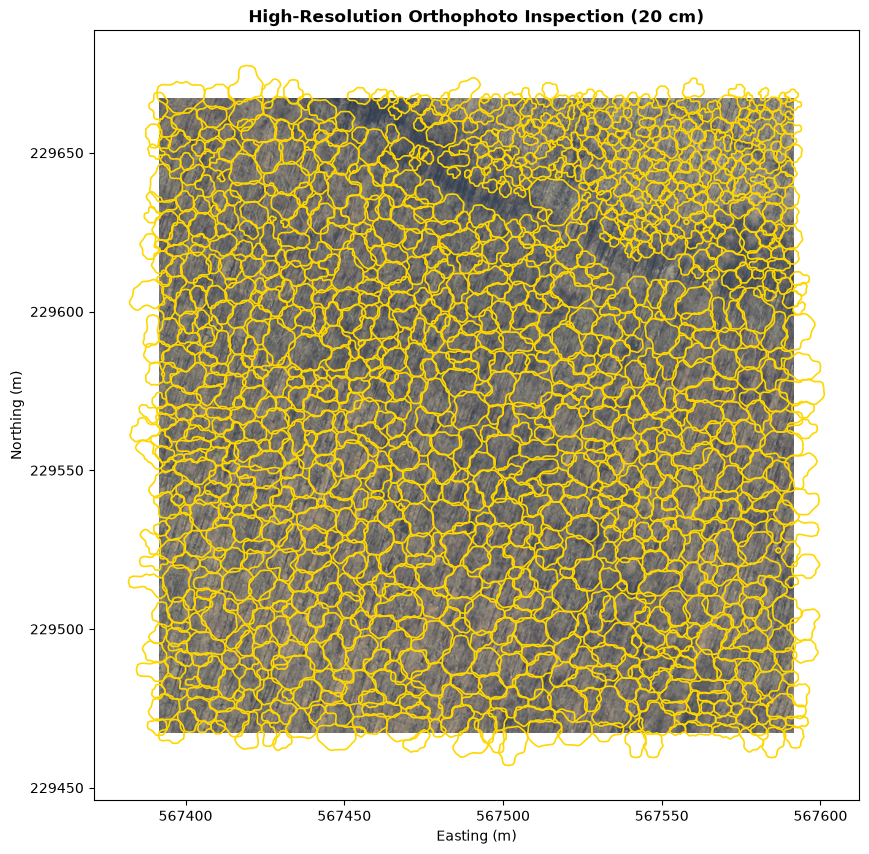

In [6]:
with rasterio.open(ortho_path) as src:
    print(f"Orthophoto Ground Resolution: {src.res}")
    print(f"Band Count: {src.count}")
    print(f"Raster CRS: {src.crs}")
    print(f"Bounding Box: {src.bounds}")

    window = rasterio.windows.Window(src.width // 2 - 500, src.height // 2 - 500, 1000, 1000)
    img_subset = src.read(window=window)
    subset_transform = src.window_transform(window)

    fig, ax = plt.subplots(figsize=(10, 10))
    show(img_subset[:3], transform=subset_transform, ax=ax, title="High-Resolution Orthophoto Inspection (20 cm)")

    minx, miny = subset_transform * (0, window.height)
    maxx, maxy = subset_transform * (window.width, 0)

    polygons_in_window = gdf_polygons.cx[minx:maxx, miny:maxy]
    if not polygons_in_window.empty:
        polygons_in_window.plot(ax=ax, facecolor="none", edgecolor="gold", linewidth=1.2)

    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")
    plt.show()

In [8]:
import geopandas as gpd

fu = gpd.read_file("../data/micro_soe/ForestUnits.shp")
print("Columns:", list(fu.columns))
print(fu.head(2))

Columns: ['RET_ID', 'EV', 'HEG_KOD', 'TAG', 'RESZLETKOD', 'TULFORMA', 'UZEMMOD', 'TERMMUTATO', 'RENDELT1', 'RENDELT2', 'RENDELT3', 'EGO_KOD', 'VEDFOK', 'REZERVTERT', 'N2000', 'FAALLT', 'FFJ_KOD', 'KOR', 'EGO_KOD_2', 'SZEKTOR', 'SZERV_KO', 'SZERV_NE', 'FAT18', 'TERULET', 'FAIZONA', 'geometry']
     RET_ID    EV  HEG_KOD  TAG RESZLETKOD  TULFORMA  UZEMMOD  TERMMUTATO  \
0  51829888  2023     4572   56          B        10        1           3   
1  51829891  2023     4572   56          C        10        1           2   

   RENDELT1  RENDELT2  ...  FFJ_KOD  KOR  EGO_KOD_2  SZEKTOR  SZERV_KO  \
0       211         0  ...      411   39          7       11     10,00   
1       211         0  ...      111   62          7       11     10,00   

            SZERV_NE  FAT18  TERULET  FAIZONA  \
0  Vértesi Erdő Zrt.      6     0.85        4   
1  Vértesi Erdő Zrt.      6     5.47        4   

                                            geometry  
0  POLYGON ((566482.98 228289.066, 566581.04 228

In [9]:
import geopandas as gpd

poly = gpd.read_file("../data/micro_soe/soe_rede_CrownPolygons.shp")
print(poly.columns)

Index(['ID', 'X', 'Y', 'KoronaTer', 'KoronaAtm', 'TorzsAtm', 'Korlap',
       'Magassag', 'Fakeszlet', 'Fafaj', 'geometry'],
      dtype='str')
